In [4]:
import os
import ssl
import numpy as np
import pandas as pd

# Khắc phục lỗi SSLCertVerificationError trên Windows khi tải dữ liệu từ máy chủ UCI
ssl._create_default_https_context = ssl._create_unverified_context

# Tạo thư mục lưu dữ liệu và hình ảnh
DATA_DIR = "../data"
IMG_DIR = "../images"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(IMG_DIR, exist_ok=True)

CSV_PATH = os.path.join(DATA_DIR, "heart_disease_uci.csv")

# Kiểm tra: Nếu đã có file CSV trong thư mục data/ thì đọc luôn, nếu chưa có mới tải từ UCI
if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
    print(f"Đã đọc dữ liệu trực tiếp từ file nội bộ: {CSV_PATH}")
else:
    from ucimlrepo import fetch_ucirepo
    print("Đang tải dữ liệu lần đầu từ máy chủ UCI...")
    heart_disease = fetch_ucirepo(id=45)
    df = pd.concat([heart_disease.data.features, heart_disease.data.targets], axis=1)
    df['target'] = (df['num'] > 0).astype(int)
    df = df.drop(columns=['num'])
    df.to_csv(CSV_PATH, index=False)
    print(f"Đã tải và lưu thành công file '{CSV_PATH}'!")

print(f"Kích thước bộ dữ liệu: {df.shape[0]} bệnh nhân x {df.shape[1]} cột")
display(df.head())

print("\nThống kê số lượng nhãn (0: Không mắc bệnh tim, 1: Mắc bệnh tim):")
print(df['target'].value_counts())

Đang tải dữ liệu lần đầu từ máy chủ UCI...
Đã tải và lưu thành công file '../data\heart_disease_uci.csv'!
Kích thước bộ dữ liệu: 303 bệnh nhân x 14 cột


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0



Thống kê số lượng nhãn (0: Không mắc bệnh tim, 1: Mắc bệnh tim):
target
0    164
1    139
Name: count, dtype: int64


In [6]:
# Kiểm tra số lượng giá trị bị khuyết ở từng cột
missing_values = df.isnull().sum()
print("Số lượng giá trị bị khuyết (Missing values) ở mỗi cột:")
print(missing_values[missing_values > 0])

# Xử lý dữ liệu khuyết: Điền giá trị khuyết bằng giá trị xuất hiện nhiều nhất (Mode) của cột đó
# (Hoặc dùng phương pháp điền trung vị/median đối với biến số)
for col in ['ca', 'thal']:
    if col in df.columns and df[col].isnull().sum() > 0:
        mode_val = df[col].mode()[0]
        df[col] = df[col].fillna(mode_val)
        print(f"Đã điền giá trị khuyết ở cột '{col}' bằng mode: {mode_val}")

print(f"\nKiểm tra lại tổng số giá trị khuyết sau khi xử lý: {df.isnull().sum().sum()}")

Số lượng giá trị bị khuyết (Missing values) ở mỗi cột:
ca      4
thal    2
dtype: int64
Đã điền giá trị khuyết ở cột 'ca' bằng mode: 0.0
Đã điền giá trị khuyết ở cột 'thal' bằng mode: 3.0

Kiểm tra lại tổng số giá trị khuyết sau khi xử lý: 0


C:\Users\caoth\AppData\Local\Temp\ipykernel_14560\902217242.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='target', data=df, palette='Set2')


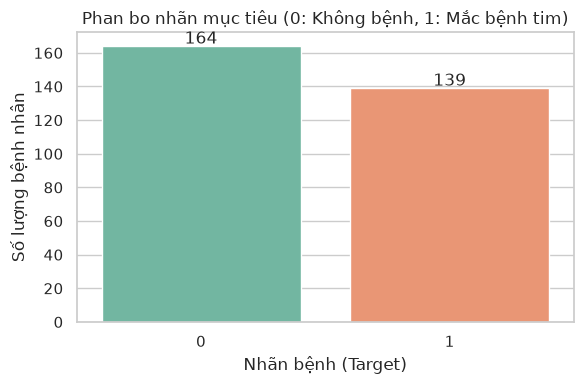

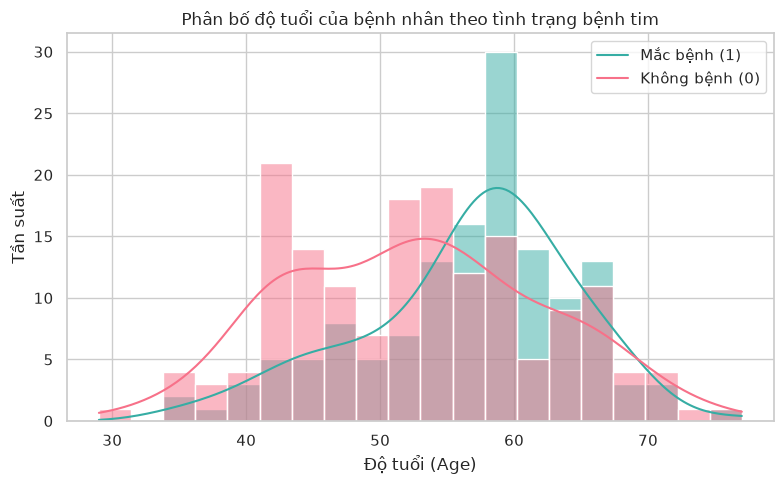

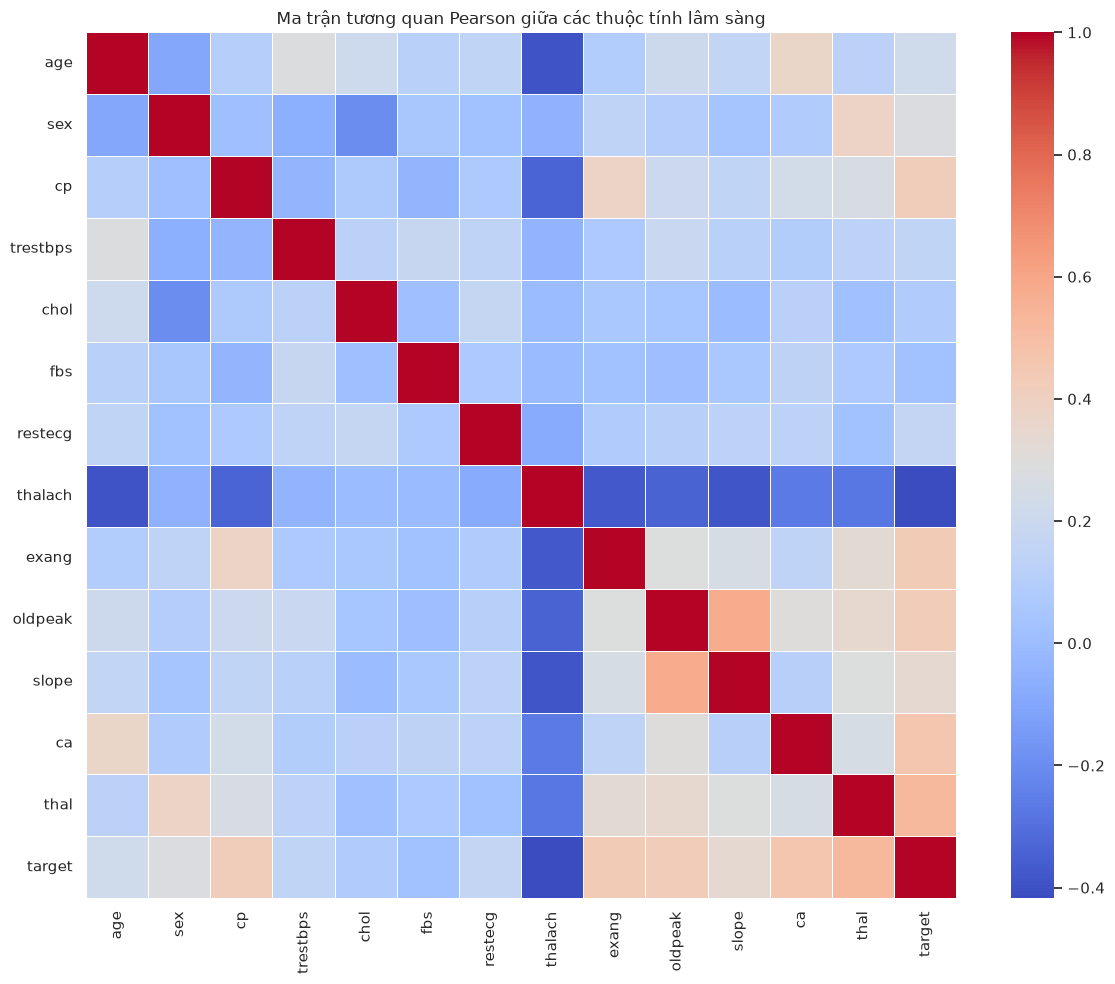

Đã vẽ và tự động lưu 3 biểu đồ EDA thành công vào thư mục 'images/'!


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình phong cách biểu đồ
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 1. Biểu đồ 1: Phân bố nhãn mục tiêu (Bệnh nhân có bệnh vs Không bệnh)
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='target', data=df, palette='Set2')
plt.title('Phan bo nhãn mục tiêu (0: Không bệnh, 1: Mắc bệnh tim)')
plt.xlabel('Nhãn bệnh (Target)')
plt.ylabel('Số lượng bệnh nhân')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, 'eda_target_distribution.png'), dpi=300)
plt.show()

# 2. Biểu đồ 2: Phân bố độ tuổi theo tình trạng bệnh
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='age', hue='target', kde=True, bins=20, palette='husl')
plt.title('Phân bố độ tuổi của bệnh nhân theo tình trạng bệnh tim')
plt.xlabel('Độ tuổi (Age)')
plt.ylabel('Tần suất')
plt.legend(['Mắc bệnh (1)', 'Không bệnh (0)'])
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, 'eda_age_distribution.png'), dpi=300)
plt.show()

# 3. Biểu đồ 3: Ma trận tương quan giữa các đặc trưng (Correlation Heatmap)
plt.figure(figsize=(12, 10))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Ma trận tương quan Pearson giữa các thuộc tính lâm sàng')
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, 'eda_correlation_heatmap.png'), dpi=300)
plt.show()

print("Đã vẽ và tự động lưu 3 biểu đồ EDA thành công vào thư mục 'images/'!")

In [8]:
from sklearn.model_selection import train_test_split

# Tách biến đặc trưng (X) và biến mục tiêu (y)
X = df.drop(columns=['target'])
y = df['target']

# Chia dữ liệu: 80% huấn luyện (Train), 20% kiểm thử (Test) có phân tầng (stratify=y) để cân đối nhãn
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Kích thước tập huấn luyện (X_train): {X_train.shape[0]} mẫu")
print(f"Kích thước tập kiểm thử (X_test):   {X_test.shape[0]} mẫu")

Kích thước tập huấn luyện (X_train): 242 mẫu
Kích thước tập kiểm thử (X_test):   61 mẫu


In [5]:
counts = df['target'].value_counts()
n_0, n_1 = counts[0], counts[1] # 164 người không bệnh (0) và 139 người có bệnh (1)
total = len(df)                 # 303 bệnh nhân

p_0 = n_0 / total
p_1 = n_1 / total

gini_root = 1 - (p_0**2 + p_1**2)
entropy_root = -(p_0 * np.log2(p_0) + p_1 * np.log2(p_1))

print(f"Tổng số mẫu tại Nút gốc: {total} [Không bệnh (0): {n_0}, Có bệnh (1): {n_1}]")
print(f"Tỷ lệ phân lớp: p_0 = {p_0:.4f}, p_1 = {p_1:.4f}")
print(f"-> Chỉ số Gini Impurity tại Nút gốc: {gini_root:.4f}")
print(f"-> Chỉ số Entropy tại Nút gốc:       {entropy_root:.4f}")

Tổng số mẫu tại Nút gốc: 303 [Không bệnh (0): 164, Có bệnh (1): 139]
Tỷ lệ phân lớp: p_0 = 0.5413, p_1 = 0.4587
-> Chỉ số Gini Impurity tại Nút gốc: 0.4966
-> Chỉ số Entropy tại Nút gốc:       0.9951


In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Khởi tạo mô hình Decision Tree (chưa cắt tỉa, mặc định max_depth=None)
dt_unpruned = DecisionTreeClassifier(criterion='gini', random_state=42)
dt_unpruned.fit(X_train, y_train)

# Dự đoán trên tập Train và Test
y_train_pred = dt_unpruned.predict(X_train)
y_test_pred = dt_unpruned.predict(X_test)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print(f"--- CÂY QUYẾT ĐỊNH CHƯA CẮT TỈA (UNPRUNED) ---")
print(f"Độ sâu thực tế của cây: {dt_unpruned.get_depth()}")
print(f"Độ chính xác trên tập Train: {train_acc * 100:.2f}% (Thường đạt 100% do Overfitting)")
print(f"Độ chính xác trên tập Test:  {test_acc * 100:.2f}%")
print(f"\nBáo cáo phân loại chi tiết trên tập Test:")
print(classification_report(y_test, y_test_pred))

--- CÂY QUYẾT ĐỊNH CHƯA CẮT TỈA (UNPRUNED) ---
Độ sâu thực tế của cây: 11
Độ chính xác trên tập Train: 100.00% (Thường đạt 100% do Overfitting)
Độ chính xác trên tập Test:  73.77%

Báo cáo phân loại chi tiết trên tập Test:
              precision    recall  f1-score   support

           0       0.81      0.67      0.73        33
           1       0.68      0.82      0.74        28

    accuracy                           0.74        61
   macro avg       0.75      0.74      0.74        61
weighted avg       0.75      0.74      0.74        61



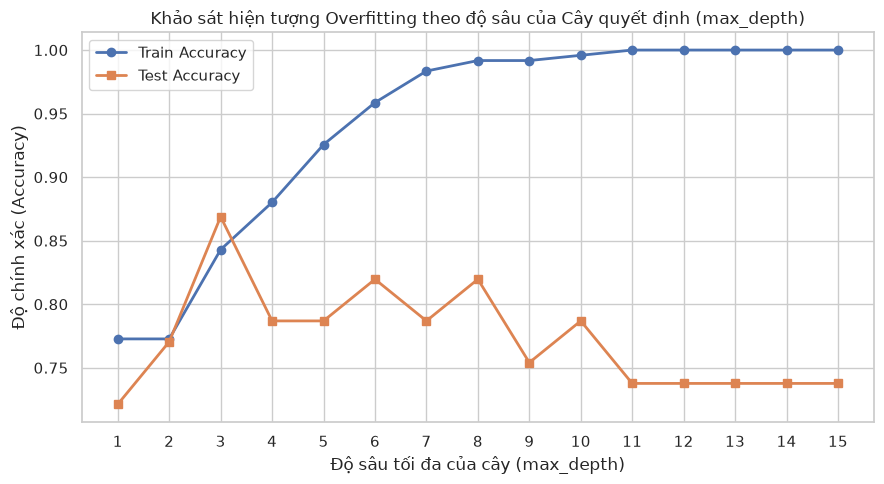

==> Độ sâu tối ưu mang lại độ chính xác trên tập Test cao nhất là: max_depth = 3


In [10]:
train_accuracies = []
test_accuracies = []
depths = range(1, 16)

for depth in depths:
    dt = DecisionTreeClassifier(criterion='gini', max_depth=depth, random_state=42)
    dt.fit(X_train, y_train)
    
    train_accuracies.append(accuracy_score(y_train, dt.predict(X_train)))
    test_accuracies.append(accuracy_score(y_test, dt.predict(X_test)))

# Vẽ biểu đồ so sánh Train vs Test theo độ sâu của cây
plt.figure(figsize=(9, 5))
plt.plot(depths, train_accuracies, marker='o', label='Train Accuracy', linewidth=2)
plt.plot(depths, test_accuracies, marker='s', label='Test Accuracy', linewidth=2)
plt.title('Khảo sát hiện tượng Overfitting theo độ sâu của Cây quyết định (max_depth)')
plt.xlabel('Độ sâu tối đa của cây (max_depth)')
plt.ylabel('Độ chính xác (Accuracy)')
plt.xticks(depths)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, 'dt_overfitting_analysis.png'), dpi=300)
plt.show()

# Tìm độ sâu tối ưu cho tập Test
best_depth = depths[np.argmax(test_accuracies)]
print(f"==> Độ sâu tối ưu mang lại độ chính xác trên tập Test cao nhất là: max_depth = {best_depth}")

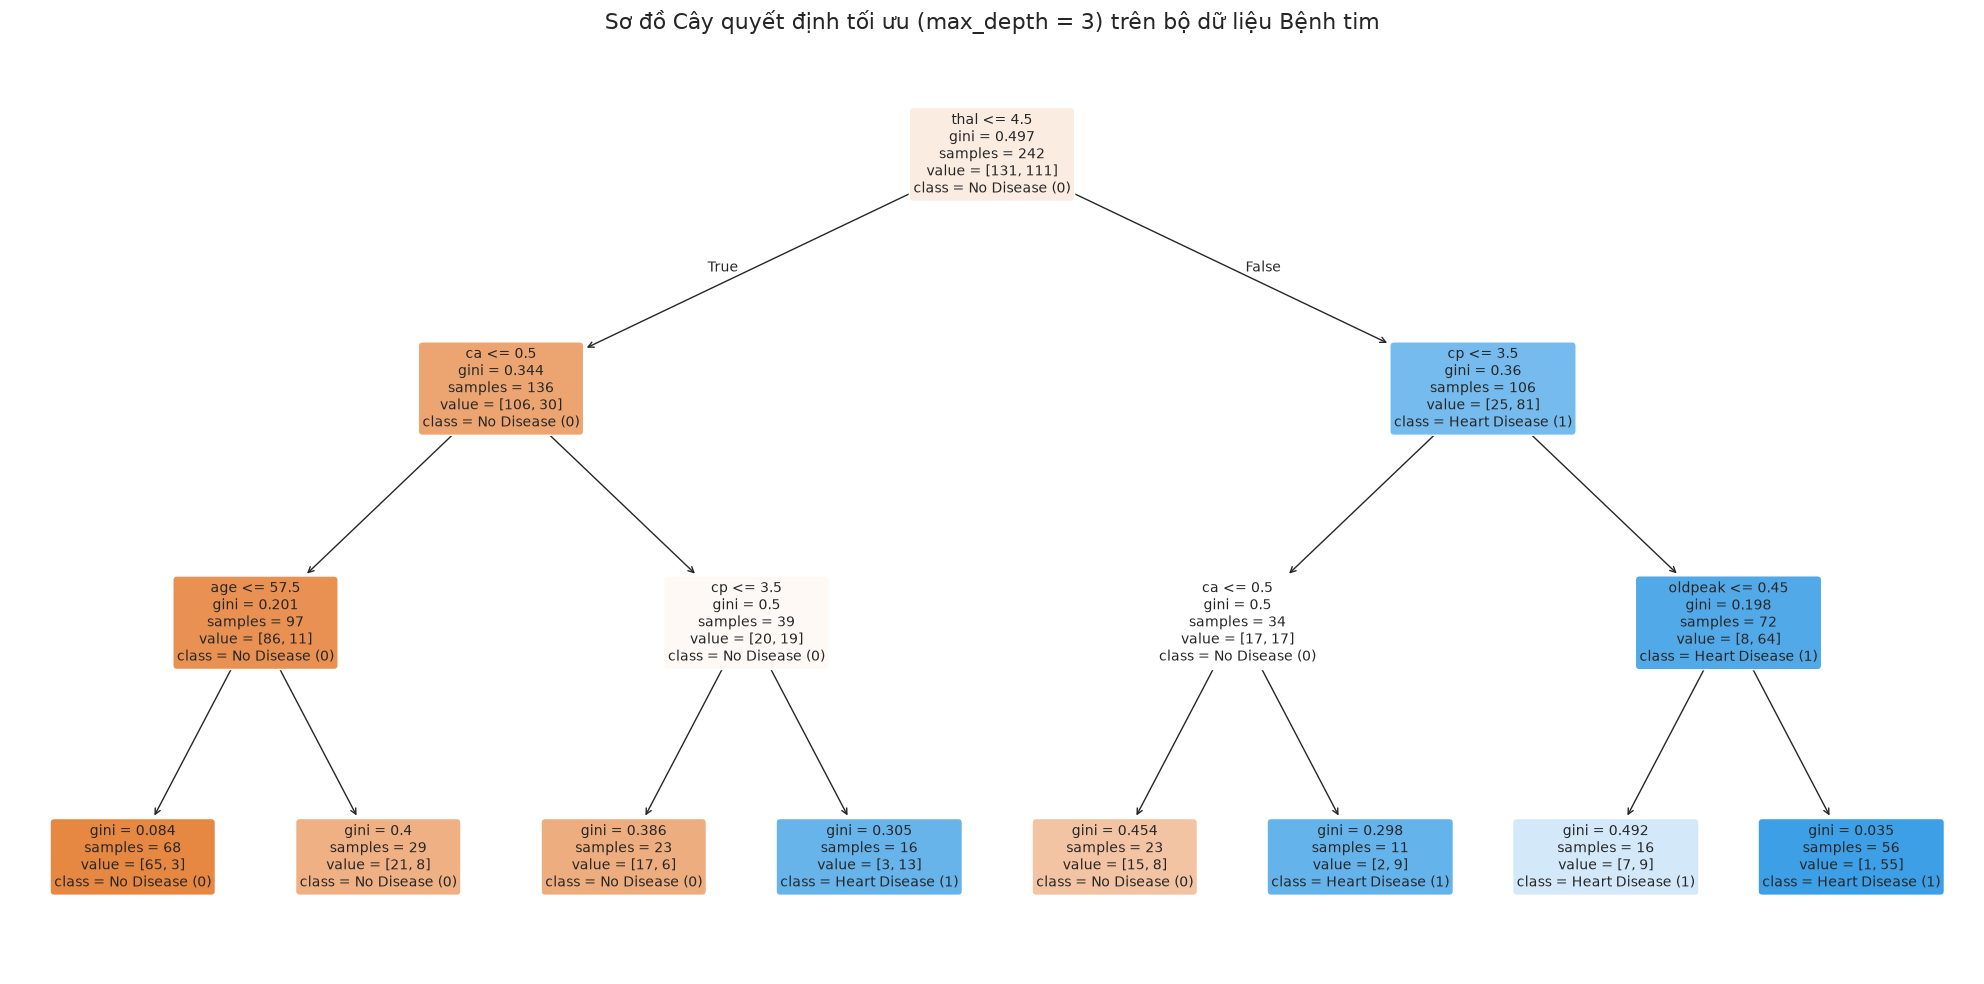

Đã huấn luyện xong Cây quyết định tối ưu và lưu sơ đồ cây vào thư mục 'images/'!


In [11]:
from sklearn.tree import plot_tree

# Huấn luyện mô hình Decision Tree với độ sâu tối ưu (ví dụ dùng best_depth vừa tìm được)
dt_optimal = DecisionTreeClassifier(criterion='gini', max_depth=best_depth, random_state=42)
dt_optimal.fit(X_train, y_train)

# Vẽ sơ đồ cây quyết định
plt.figure(figsize=(20, 10))
plot_tree(
    dt_optimal, 
    feature_names=X.columns, 
    class_names=['No Disease (0)', 'Heart Disease (1)'], 
    filled=True, 
    rounded=True,
    fontsize=10
)
plt.title(f'Sơ đồ Cây quyết định tối ưu (max_depth = {best_depth}) trên bộ dữ liệu Bệnh tim', fontsize=16)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, 'decision_tree_structure.png'), dpi=300)
plt.show()

print("Đã huấn luyện xong Cây quyết định tối ưu và lưu sơ đồ cây vào thư mục 'images/'!")

In [12]:
from sklearn.ensemble import RandomForestClassifier

# Khởi tạo mô hình Random Forest (100 cây, bật oob_score để kiểm định chéo nội tại)
rf_model = RandomForestClassifier(
    n_estimators=100, 
    criterion='gini', 
    max_features='sqrt', 
    oob_score=True, 
    random_state=42, 
    n_jobs=-1
)

# Huấn luyện trên tập Train
rf_model.fit(X_train, y_train)

# Đánh giá điểm Out-of-Bag (OOB Score)
print(f"Điểm kiểm định Out-of-Bag (OOB Accuracy) của Random Forest: {rf_model.oob_score_ * 100:.2f}%")

Điểm kiểm định Out-of-Bag (OOB Accuracy) của Random Forest: 78.93%


In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

# Danh sách các mô hình đã huấn luyện
models_to_evaluate = {
    "Decision Tree (Unpruned)": dt_unpruned,
    f"Decision Tree (Depth={best_depth})": dt_optimal,
    "Random Forest (100 trees)": rf_model
}

evaluation_results = []

for name, model in models_to_evaluate.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None
    
    evaluation_results.append({
        "Mô hình": name,
        "Train Accuracy (%)": round(accuracy_score(y_train, model.predict(X_train)) * 100, 2),
        "Test Accuracy (%)": round(accuracy_score(y_test, y_pred) * 100, 2),
        "Precision (%)": round(precision_score(y_test, y_pred) * 100, 2),
        "Recall (%)": round(recall_score(y_test, y_pred) * 100, 2),
        "F1-Score (%)": round(f1_score(y_test, y_pred) * 100, 2),
        "ROC-AUC": round(roc_auc_score(y_test, y_prob), 4) if y_prob is not None else "N/A"
    })

results_df = pd.DataFrame(evaluation_results)
print("=== BẢNG SO SÁNH KẾT QUẢ THỰC NGHIỆM ===")
display(results_df)

=== BẢNG SO SÁNH KẾT QUẢ THỰC NGHIỆM ===


,Mô hình,Train Accuracy (%),Test Accuracy (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC
0,Decision Tree (Unpruned),100.0,73.77,67.65,82.14,74.19,0.7440
1,Decision Tree (Depth=3),84.3,86.89,85.71,85.71,85.71,0.8712
2,Random Forest (100 trees),100.0,88.52,83.87,92.86,88.14,0.9518


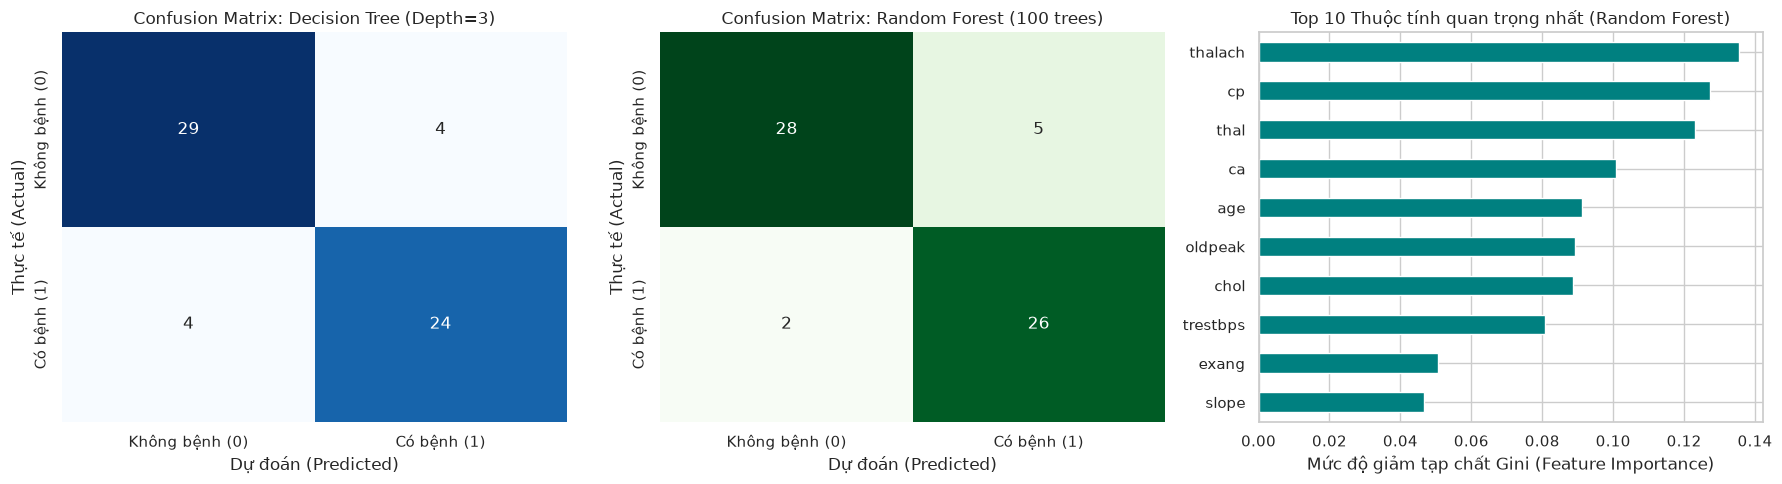

Đã vẽ xong biểu đồ đánh giá và lưu vào thư mục 'images/'!


In [14]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion Matrix: Decision Tree tối ưu
cm_dt = confusion_matrix(y_test, dt_optimal.predict(X_test))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Không bệnh (0)', 'Có bệnh (1)'], yticklabels=['Không bệnh (0)', 'Có bệnh (1)'])
axes[0].set_title(f'Confusion Matrix: Decision Tree (Depth={best_depth})')
axes[0].set_xlabel('Dự đoán (Predicted)')
axes[0].set_ylabel('Thực tế (Actual)')

# 2. Confusion Matrix: Random Forest
cm_rf = confusion_matrix(y_test, rf_model.predict(X_test))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', cbar=False, ax=axes[1],
            xticklabels=['Không bệnh (0)', 'Có bệnh (1)'], yticklabels=['Không bệnh (0)', 'Có bệnh (1)'])
axes[1].set_title('Confusion Matrix: Random Forest (100 trees)')
axes[1].set_xlabel('Dự đoán (Predicted)')
axes[1].set_ylabel('Thực tế (Actual)')

# 3. Top 10 Feature Importances từ Random Forest
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
top10_features = importances.nlargest(10).sort_values(ascending=True)
top10_features.plot(kind='barh', color='teal', ax=axes[2])
axes[2].set_title('Top 10 Thuộc tính quan trọng nhất (Random Forest)')
axes[2].set_xlabel('Mức độ giảm tạp chất Gini (Feature Importance)')

plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, 'rf_evaluation_and_importance.png'), dpi=300)
plt.show()

print("Đã vẽ xong biểu đồ đánh giá và lưu vào thư mục 'images/'!")

In [15]:
import pandas as pd
import numpy as np

# 1. Giả lập thông tin của 1 bệnh nhân mới cần dự đoán
# Thứ tự 13 đặc trưng phải khớp chính xác với 13 cột trong X_train của bạn:
# ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

# Ví dụ: Bệnh nhân Nam (1), 60 tuổi, đau ngực loại 4, huyết áp 160, cholesterol 280, ...
new_patient_data = [[60, 1, 4, 160, 280, 0, 2, 120, 1, 2.5, 2, 2.0, 7.0]]

# Đưa vào DataFrame với đúng tên các cột đặc trưng
X_new = pd.DataFrame(new_patient_data, columns=X.columns)

# 2. Sử dụng mô hình Random Forest đã huấn luyện ở Ngày 5 để dự đoán
prediction = rf_model.predict(X_new)         # Kết quả: 0 (Không bệnh) hoặc 1 (Có bệnh)
prediction_proba = rf_model.predict_proba(X_new) # Xác suất % cho từng lớp

# 3. Hiển thị kết quả chẩn đoán chi tiết
print("=== KẾT QUẢ CHẨN ĐOÁN LÂM SÀNG CHO BỆNH NHÂN MỚI ===")
print(f"Các chỉ số đầu vào của bệnh nhân: {list(X_new.values[0])}")
print("-" * 50)

if prediction[0] == 1:
    risk_percentage = prediction_proba[0][1] * 100
    print(f"👉 Chẩn đoán từ Random Forest: CÓ NGUY CƠ MẮC BỆNH TIM (Lớp 1)")
    print(f"📊 Mức độ tin cậy của mô hình: {risk_percentage:.2f}%")
else:
    safe_percentage = prediction_proba[0][0] * 100
    print(f"👉 Chẩn đoán từ Random Forest: AN TOÀN - KHÔNG MẮC BỆNH TIM (Lớp 0)")
    print(f"📊 Mức độ tin cậy của mô hình: {safe_percentage:.2f}%")

=== KẾT QUẢ CHẨN ĐOÁN LÂM SÀNG CHO BỆNH NHÂN MỚI ===
Các chỉ số đầu vào của bệnh nhân: [np.float64(60.0), np.float64(1.0), np.float64(4.0), np.float64(160.0), np.float64(280.0), np.float64(0.0), np.float64(2.0), np.float64(120.0), np.float64(1.0), np.float64(2.5), np.float64(2.0), np.float64(2.0), np.float64(7.0)]
--------------------------------------------------
👉 Chẩn đoán từ Random Forest: CÓ NGUY CƠ MẮC BỆNH TIM (Lớp 1)
📊 Mức độ tin cậy của mô hình: 100.00%
